# Лекция 6. Векторный поиск: демонстрация

**Курс «От интеллектуального поиска к интеллектуальным агентам», ВМК МГУ.** Блокнот повторяет лекцию по шагам на «Евгении Онегине» и корпусе ParaPhraser.

| шаг | что делаем |
|---|---|
| 0 | данные и готовые векторы |
| 1 | ближайшие строфы к запросу |
| 1а | какая строка нашлась: объяснение выдачи |
| 1б | запрос по-английски к русскому тексту |
| 2 | метрики: три модели и BM25F |
| 2а | нарезка строф на окна: максимум и среднее |
| 2б | корпус курса: положение о рецензировании, вопрос о сроке |
| 3 | InfoNCE вручную и температура |
| 4 | матрица пакета на парах перефразирований |
| 5 | игрушечное контрастивное обучение |
| 6 | учебный HNSW и путь поиска |
| 7 | мини-практика: HNSW на 100 строфах |
| 8 | FAISS на 13 738 заголовках |
| 8а | почти-дубликаты среди 14 738 заголовков |
| 8б | двоичные векторы: знаки координат |
| 9 | инструмент `search_vectors` для агента |

При первом запуске три модели скачиваются с Hugging Face, всего около 3 ГБ, дальше они берутся из локального кэша. Модели не обучаются, только кодируют тексты. Исключение есть шаг 5: там обучается линейное отображение из 20 чисел в 2, это секунды.

In [1]:
import os, sys, csv, json, time
sys.path.insert(0, "scripts")
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from search_bm25 import Pipeline, Index, load_qrels, precision_at_k, recall_at_k, reciprocal_rank, ndcg_at_k
pd.set_option("display.max_colwidth", 60)

## Шаг 0. Данные и готовые векторы

360 строф и 16 запросов занятия 5. Векторы строф посчитаны заранее программой `scripts/embed_onegin.py` тремя моделями и лежат в `data/emb_*.npy`. Векторы нормированы, поэтому косинус равен скалярному произведению.

In [2]:
rows = list(csv.DictReader(open("data/onegin_stanzas.csv", encoding="utf-8")))
ids = [r["id"] for r in rows]; first = {r["id"]: r["название"] for r in rows}
qrels = load_qrels("data/queries_onegin.csv")
E = {m: np.load(f"data/emb_{m}.npy") for m in ["minilm", "bgem3", "scirus"]}
idx = Index([{"название": r["название"], "текст": r["текст"]} for r in rows], Pipeline(), {"название": 2.0, "текст": 1.0}, ids)
print("строф:", len(rows), "| запросов:", len(qrels))
for m, X in E.items():
    print(f"{m:7} векторы {X.shape}, длина первого вектора {np.linalg.norm(X[0]):.3f}")

строф: 360 | запросов: 16
minilm  векторы (360, 384), длина первого вектора 1.000
bgem3   векторы (360, 1024), длина первого вектора 1.000
scirus  векторы (360, 312), длина первого вектора 1.000


## Шаг 1. Ближайшие строфы к запросу

Запрос кодируется той же моделью, что и строфы. Дальше одно умножение матрицы на вектор и сортировка. Сравним с поиском по словам из занятия 5.

In [3]:
from sentence_transformers import SentenceTransformer
bge = SentenceTransformer("BAAI/bge-m3", device="cpu")

def vsearch(q, k=5, X=E["bgem3"], model=bge):
    v = model.encode([q], normalize_embeddings=True)[0]
    s = X @ v; top = np.argsort(-s)[:k]
    return [(ids[i], first[ids[i]], round(float(s[i]), 3)) for i in top]

for q in ["поединок", "описание осени", "Я вас люблю к чему лукавить"]:
    print(f"\n=== {q}")
    print("векторы BGE-M3:", vsearch(q))
    print("слова BM25F:   ", [(d, first[d], round(sc, 2)) for d, sc in idx.bm25f(q, k=5)] or "пусто")


=== поединок


векторы BGE-M3: [('6.IX', 'То был приятный, благородный,', 0.459), ('6.XXX', 'Теперь сходитесь».', 0.446), ('6.XXVI', 'Опершись на плотину, Ленский', 0.431), ('1.XVI', 'Уж темно: в санки он садится.', 0.426), ('5.XLV', 'Но ей нельзя. Нельзя? Но что же?', 0.418)]
слова BM25F:    пусто

=== описание осени


векторы BGE-M3: [('4.XL', 'Но наше северное лето,', 0.541), ('7.XXIX', 'Ее прогулки длятся доле.', 0.515), ('7.III', 'Или, не радуясь возврату', 0.502), ('5.I', 'В тот год осенняя погода', 0.5), ('8.XXIX', 'Любви все возрасты покорны;', 0.499)]
слова BM25F:    [('5.I', 'В тот год осенняя погода', 6.94), ('7.XXIX', 'Ее прогулки длятся доле.', 4.25), ('8.XXIX', 'Любви все возрасты покорны;', 4.21), ('8.XI', 'Но грустно думать, что напрасно', 4.17), ('4.XL', 'Но наше северное лето,', 4.13)]

=== Я вас люблю к чему лукавить


векторы BGE-M3: [('4.XIX', 'А что? Да так. Я усыпляю', 0.569), ('4.XXII', 'Кого ж любить? Кому же верить?', 0.559), ('8.ПО', 'Письмо Онегина к Татьяне', 0.55), ('4.VII', 'Чем меньше женщину мы любим,', 0.543), ('4.XXIX', 'Тут непременно вы найдете', 0.532)]
слова BM25F:    [('8.XLVII', 'А счастье было так возможно,', 18.11), ('4.XVI', 'Мечтам и годам нет возврата;', 8.83), ('8.XVI', 'Люблю я очень это слово,', 7.78), ('1.XXX', 'Увы, на разные забавы', 6.97), ('8.XLIII', 'Онегин, я тогда моложе,', 5.96)]


На «поединок» поиск по словам пуст. Само слово в романе есть: «Пред поединком Ольгу видеть» (6.XIII) и «Убив на поединке друга» (8.XII). Стеммер даёт этим формам основу «поединк», запросу основу «поединок», и основы не совпадают. Векторный поиск ставит первыми вызов, саму сцену дуэли и подготовку к ней. На «описание осени» векторы находят «Уж небо осенью дышало». На точную цитату «Я вас люблю» векторы отдают строфы о любви вообще, поиск по словам находит нужную строфу 8.XLVII первой.

## Шаг 1а. Какая строка нашлась

Векторный поиск возвращает строфу целиком и не говорит, чем она подошла. Каждая строка найденной строфы кодируется той же моделью и сравнивается с запросом: строка с наибольшим косинусом показывает место, которое модель считает ответом.

In [4]:
by_id = {r["id"]: r for r in rows}
def explain(q, sid, model=bge, top=3):
    lines = [l.strip() for l in by_id[sid]["текст"].split(" / ") if l.strip()]
    L = model.encode(lines, normalize_embeddings=True); v = model.encode([q], normalize_embeddings=True)[0]
    s = L @ v; order = np.argsort(-s)[:top]
    return [(lines[i], round(float(s[i]), 3)) for i in order]

for q, sid in [("поединок", "6.XXX"), ("описание осени", "4.XL"), ("сон Татьяны с медведем", "5.XII")]:
    print(f"{q} -> {sid}:", explain(q, sid))

поединок -> 6.XXX: [('«Теперь сходитесь».', 0.547), ('Не преставая наступать,', 0.541), ('Онегин выстрелил… Пробили', 0.501)]


описание осени -> 4.XL: [('Уж небо осенью дышало,', 0.648), ('Стоял ноябрь уж у двора.', 0.546), ('Но наше северное лето,', 0.48)]


сон Татьяны с медведем -> 5.XII: [('Татьяна ропщет на ручей;', 0.575), ('Пошла\xa0– и что ж? медведь за ней!', 0.52), ('Татьяна ах! а он реветь,', 0.519)]


«Поединок» указывает на «Теперь сходитесь», «описание осени» на «Уж небо осенью дышало», вторым идёт «Стоял ноябрь уж у двора». У запроса о сне Татьяны лучшие строки содержат Татьяну или медведя: вектор строфы собирает обе темы запроса. Такую строку агент кладёт в пометку «найдено по смыслу», и её легко сверить с текстом.

## Шаг 1б. Запрос по-английски

BGE-M3 обучена на текстах больше чем ста языков, среди её обучающих пар есть переводы. Зададим запросы к русскому роману по-английски.

In [5]:
pairs_ru_en = [("описание осени", "a description of autumn"), ("кто такой Зарецкий", "who is Zaretsky"),
               ("сон Татьяны с медведем", "Tatiana's dream with a bear"), ("утро в Петербурге", "morning in Petersburg")]
for ru, en in pairs_ru_en:
    print(f"{ru:28} векторы: {[d for d, _, _ in vsearch(ru, 3)]}")
    print(f"{en:28} векторы: {[d for d, _, _ in vsearch(en, 3)]}   слова: {[d for d, _ in idx.bm25f(en, k=3)] or 'пусто'}")

описание осени               векторы: ['4.XL', '7.XXIX', '7.III']


a description of autumn      векторы: ['4.XL', '7.XXIX', '5.I']   слова: ['4.XXVIII']


кто такой Зарецкий           векторы: ['6.IV', '6.XXVII', '6.XXVI']


who is Zaretsky              векторы: ['6.IV', '6.XXVII', '6.XXVI']   слова: пусто


сон Татьяны с медведем       векторы: ['5.XI', '5.XII', '5.XXIV']


Tatiana's dream with a bear  векторы: ['5.XI', '7.XV', '5.V']   слова: ['5.XXVII', '4.XXVIII']
утро в Петербурге            векторы: ['1.XXXV', '5.I', '3.XXXIII']


morning in Petersburg        векторы: ['3.XXXIII', '1.XXXV', '6.XXIV']   слова: ['4.XXX']


Английский запрос находит те же строфы, что русский: 4.XL на осень, 6.IV на Зарецкого, 5.XI на сон Татьяны. Поиск по словам на английских запросах находит только случайные совпадения с французскими и латинскими вкраплениями романа: «Tatiana» из куплета Трике «Réveillez-vous, belle endormie» (5.XXVII), «in» из «in-quarto» (4.XXX). Нужных строф среди них нет. На семи запросах материала английские дают NDCG@10 0,48, русские 0,56 (раздел 5.5 материала).

## Шаг 2. Метрики: три модели и BM25F

Те же функции метрик, что на занятии 5.

In [6]:
models = {"minilm": SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2", device="cpu"),
          "bgem3": bge,
          "scirus": SentenceTransformer("mlsa-iai-msu-lab/sci-rus-tiny", device="cpu")}
Qv = {m: models[m].encode([q for _, q, _ in qrels], normalize_embeddings=True) for m in models}

def evaluate(rank):
    out = {"P@5": 0, "R@10": 0, "MRR": 0, "NDCG@10": 0}; per = {}
    for j, (qid, q, rel) in enumerate(qrels):
        r = rank(j, q)
        out["P@5"] += precision_at_k(r, rel, 5); out["R@10"] += recall_at_k(r, rel, 10)
        out["MRR"] += reciprocal_rank(r, rel); n = ndcg_at_k(r, rel, 10); out["NDCG@10"] += n; per[q] = round(n, 2)
    return {k: round(v / len(qrels), 3) for k, v in out.items()}, per

res = {"BM25F": evaluate(lambda j, q: [d for d, _ in idx.bm25f(q, k=10)])}
for m in models:
    res[m] = evaluate(lambda j, q, m=m: [ids[i] for i in np.argsort(-(E[m] @ Qv[m][j]))[:10]])
pd.DataFrame({k: v[0] for k, v in res.items()}).T

,P@5,R@10,MRR,NDCG@10
BM25F,0.263,0.698,0.823,0.689
minilm,0.225,0.477,0.502,0.415
bgem3,0.225,0.679,0.767,0.649
scirus,0.038,0.115,0.094,0.081


In [7]:
pd.DataFrame({k: v[1] for k, v in res.items()})[["BM25F", "bgem3", "minilm"]]

,BM25F,bgem3,minilm
мой дядя самых честных правил,1.00,1.00,0.50
Я вас люблю к чему лукавить,1.00,0.00,0.00
Любви все возрасты покорны,1.00,1.00,1.00
Привычка свыше нам дана замена счастию она,1.00,1.00,0.00
Вы мне писали не отпирайтесь,0.76,0.76,0.29
письмо Татьяны,0.88,0.52,0.46
зима крестьянин торжествуя,0.90,0.89,0.24
брусничная вода,1.00,0.67,0.76
Москва,0.84,0.76,0.80
кто такой Зарецкий,0.23,0.64,0.32


В среднем ни одна модель не обогнала BM25F. По запросам видно, что BGE-M3 лучше на вопросе о Зарецком, описании осени, сне Татьяны, имени героини и хуже на точной цитате и письме Татьяны. SciRus-tiny обучена на научных статьях и на стихах почти ничего не находит.

## Шаг 2а. Нарезка строф на окна

У MiniLM предел входа 128 токенов, и 95 строф из 360 длиннее. Режем каждую строфу на окна по четыре строки с шагом две строки, кодируем окна и собираем оценку строфы двумя способами: максимумом и средним по её окнам.

In [8]:
mlm = models["minilm"]
pieces, owner = [], []
for i, r in enumerate(rows):
    ls = [l.strip() for l in r["текст"].split(" / ") if l.strip()]
    for j in range(0, max(1, len(ls) - 3), 2):
        pieces.append("\n".join(ls[j:j + 4])); owner.append(i)
owner = np.array(owner)
Pw = mlm.encode(pieces, normalize_embeddings=True, batch_size=64)

def chunk_rank(j, q, agg):
    s = Pw @ Qv["minilm"][j]
    if agg == "max":
        sc = np.full(len(ids), -9.0); np.maximum.at(sc, owner, s)
    else:
        tot = np.zeros(len(ids)); cnt = np.zeros(len(ids)); np.add.at(tot, owner, s); np.add.at(cnt, owner, 1); sc = tot / cnt
    return [ids[i] for i in np.argsort(-sc)[:10]]

print("окон:", len(pieces))
pd.DataFrame({"строфа целиком": res["minilm"][0],
              "окна, максимум": evaluate(lambda j, q: chunk_rank(j, q, "max"))[0],
              "окна, среднее": evaluate(lambda j, q: chunk_rank(j, q, "mean"))[0]}).T

окон: 2275


,P@5,R@10,MRR,NDCG@10
строфа целиком,0.225,0.477,0.502,0.415
"окна, максимум",0.225,0.681,0.587,0.534
"окна, среднее",0.112,0.427,0.370,0.323


Окно из четырёх строк укладывается в предел модели, и сборка максимумом поднимает NDCG@10 с 0,415 до 0,534. Сборка средним возвращает размытость целой строфы и опускает его до 0,323. У BGE-M3 тот же приём даёт 0,700 при 0,689 у BM25F (раздел 2.3 материала). Кодирование 2275 окон моделью BGE-M3 на процессоре занимает минуты, поэтому здесь показана MiniLM.

## Шаг 2б. Корпус курса: положение о рецензировании

31 запись положения о рецензировании и 16 вопросов редактора и автора из занятия 5. Запись кодируется как «название. формулировка».

In [9]:
crow = list(csv.DictReader(open("data/corpus_Aprime_standards.csv", encoding="utf-8")))
cids = [r["id"] for r in crow]; ctitle = {r["id"]: r["название"] for r in crow}
cq = load_qrels("data/queries_Aprime.csv")
cidx = Index([{"название": r["название"], "формулировка": r["формулировка"]} for r in crow], Pipeline(), {"название": 2.0, "формулировка": 1.0}, cids)
CE = bge.encode([r["название"] + ". " + r["формулировка"] for r in crow], normalize_embeddings=True)
CQ = bge.encode([q for _, q, _ in cq], normalize_embeddings=True)

def cmetrics(rank):
    out = {"P@5": 0, "R@10": 0, "MRR": 0, "NDCG@10": 0}
    for j, (qid, q, rel) in enumerate(cq):
        r = rank(j, q); out["P@5"] += precision_at_k(r, rel, 5); out["R@10"] += recall_at_k(r, rel, 10)
        out["MRR"] += reciprocal_rank(r, rel); out["NDCG@10"] += ndcg_at_k(r, rel, 10)
    return {k: round(v / len(cq), 3) for k, v in out.items()}

words = lambda j, q: [d for d, _ in cidx.bm25f(q, k=10)]
vecs = lambda j, q: [cids[i] for i in np.argsort(-(CE @ CQ[j]))[:10]]
pd.DataFrame({"BM25F": cmetrics(words), "BGE-M3": cmetrics(vecs)}).T

,P@5,R@10,MRR,NDCG@10
BM25F,0.338,0.753,0.906,0.753
BGE-M3,0.438,0.950,1.000,0.916


In [10]:
j = [qid for qid, _, _ in cq].index("q05"); q = cq[j][1]
print(q)
print("слова:  ", [(d, ctitle[d]) for d in words(j, q)[:3]])
print("векторы:", [(d, ctitle[d]) for d in vecs(j, q)[:3]])

Сколько недель даётся на подготовку отзыва
слова:   [('R82', '8.2 Использование ИИ-инструментов'), ('S01', 'Раздел 1. Область применения'), ('T11', 'ИИ-инструмент')]
векторы: [('R66', '6.6 Срок рецензирования'), ('R91', '9.1 Повторная подача'), ('R64', '6.4 Ответ на замечания')]


На корпусе коротких норм BGE-M3 обгоняет поиск по словам с запасом. Вопрос о сроке не содержит слова «срок»: поиск по словам находит записи с общей основой «подготовк», векторный поиск ставит пункт 6.6 «Срок рецензирования» (R66) первым. Этот вопрос поиск по словам не находил с занятия 1.

## Шаг 3. InfoNCE вручную и температура

Запрос «дуэль Онегина и Ленского», позитив есть сцена 6.XXX, негативы есть пять других строф. Трудные негативы 6.IX (вызов на дуэль) и 2.XV «Он слушал Ленского с улыбкой» (имена героев без дуэли). Строфа 6.XXVI в негативы не берётся: она размечена как ответ. Посчитаем потерю по формуле

$$L = -\log \frac{\exp(s^+/\tau)}{\exp(s^+/\tau) + \sum_j \exp(s_j^-/\tau)}.$$

In [11]:
q = bge.encode(["дуэль Онегина и Ленского"], normalize_embeddings=True)[0]
cand = ["6.XXX", "6.IX", "2.XV", "4.XXV", "5.II", "1.I"]
s = np.array([float(E["bgem3"][ids.index(c)] @ q) for c in cand])
def softmax(z): z = z - z.max(); e = np.exp(z); return e / e.sum()
tab = pd.DataFrame({"строфа": cand, "первая строка": [first[c] for c in cand], "косинус": s.round(3)})
for tau in [1.0, 0.1, 0.05]:
    p = softmax(s / tau); tab[f"p при τ={tau}"] = p.round(3)
    print(f"τ = {tau}: вероятность позитива {p[0]:.3f}, потеря {-np.log(p[0]):.3f}")
tab

τ = 1.0: вероятность позитива 0.178, потеря 1.728
τ = 0.1: вероятность позитива 0.215, потеря 1.535
τ = 0.05: вероятность позитива 0.171, потеря 1.766


,строфа,первая строка,косинус,p при τ=1.0,p при τ=0.1,p при τ=0.05
0,6.XXX,Теперь сходитесь».,0.499,0.178,0.215,0.171
1,6.IX,"То был приятный, благородный,",0.550,0.187,0.360,0.478
2,2.XV,Он слушал Ленского с улыбкой.,0.532,0.184,0.300,0.332
3,4.XXV,Час от часу плененный боле,0.349,0.153,0.048,0.009
4,5.II,"Зима!.. Крестьянин, торжествуя,",0.312,0.147,0.033,0.004
5,1.I,"Мой дядя самых честных правил,",0.336,0.151,0.043,0.007


Модель ставит выше позитива два трудных негатива: вызов на дуэль 6.IX и строфу 2.XV с именами героев. Потеря большая, и обучение на таком примере потянуло бы сцену к запросу. При τ = 0,05 вероятность позитива ниже, чем при τ = 0,1: малая температура усиливает трудные негативы, стоящие выше позитива.

## Шаг 4. Матрица пакета на парах перефразирований

Восемь пар заголовков из ParaPhraser, размеченных как перефразирования. Для каждой строки позитив стоит на диагонали, остальные столбцы суть негативы внутри пакета.

In [12]:
test = [json.loads(l) for l in open("data/paraphraser_test.jsonl", encoding="utf-8")]
pos = [p for p in test if p["class"] == "1"]
rng = np.random.default_rng(7); pick = [pos[i] for i in rng.choice(len(pos), 8, replace=False)]
A = models["minilm"].encode([p["text_1"] for p in pick], normalize_embeddings=True)
B = models["minilm"].encode([p["text_2"] for p in pick], normalize_embeddings=True)
S = A @ B.T
print("верный столбец найден в", int((S.argmax(1) == np.arange(8)).sum()), "строках из 8")
print("средняя потеря InfoNCE при τ = 0,05:", round(float(np.mean([-np.log(softmax(S[i] / 0.05)[i]) for i in range(8)])), 4))
pd.DataFrame(S.round(2), index=[p["text_1"][:40] for p in pick], columns=[f"пара {i+1}" for i in range(8)])

верный столбец найден в 8 строках из 8
средняя потеря InfoNCE при τ = 0,05: 0.0001


,пара 1,пара 2,пара 3,пара 4,пара 5,пара 6,пара 7,пара 8
Черногория требует извинений от организа,0.97,0.05,0.32,0.20,0.26,0.33,0.24,0.26
ЦБ запретил «Росгосстраху» продавать пол,0.13,0.74,0.07,0.36,0.24,0.26,0.15,0.11
"Пушилин: альтернатива соблюдению ""Минска",0.17,0.13,0.99,0.31,0.35,0.27,0.46,0.49
"Минздрав выступает против возвращения ""к",0.18,0.20,0.39,0.94,0.40,0.31,0.31,0.30
Лавров опроверг данные о содействии осво,0.18,0.23,0.40,0.38,0.93,0.23,0.26,0.44
Концерн «Алмаз-Антей» обжаловал санкции,0.36,0.12,0.26,0.33,0.22,0.98,0.05,0.34
Конференция по ДНЯО завершилась без итог,0.15,0.20,0.30,0.19,0.16,0.04,0.92,0.16
Минобороны: НАТО в Атлантике отработает,0.16,0.11,0.50,0.26,0.36,0.33,0.29,0.96


## Шаг 5. Игрушечное контрастивное обучение

Шесть групп по двенадцать примеров, каждый пример есть вектор из 20 чисел. Модель есть линейное отображение в плоскость с нормировкой на окружность. На каждом шаге из каждой группы берутся два примера: якорь и позитив. Потеря InfoNCE, $\tau = 0{,}2$.

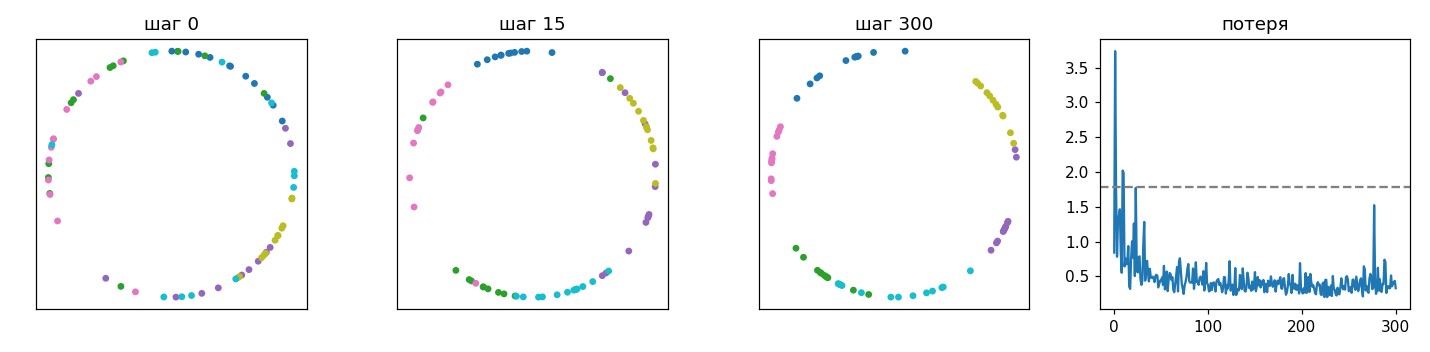

потеря в начале 1.467 | в конце 0.438 | ln 6 = 1.792


In [13]:
import torch
torch.manual_seed(0); rng = np.random.default_rng(0)
G, per, din = 6, 12, 20
protos = rng.normal(0, 1, (G, din))
X = np.concatenate([protos[g] + rng.normal(0, 0.9, (per, din)) for g in range(G)]).astype("float32"); y = np.repeat(np.arange(G), per)
W = torch.nn.Linear(din, 2, bias=False); opt = torch.optim.Adam(W.parameters(), lr=0.03); Xt = torch.tensor(X)
snaps, curve = {}, []
for step in range(301):
    if step in (0, 15, 300):
        with torch.no_grad(): snaps[step] = torch.nn.functional.normalize(W(Xt), dim=1).numpy()
    a, p = zip(*[rng.choice(np.where(y == g)[0], 2, replace=False) for g in range(G)])
    za = torch.nn.functional.normalize(W(Xt[list(a)]), dim=1); zp = torch.nn.functional.normalize(W(Xt[list(p)]), dim=1)
    loss = torch.nn.functional.cross_entropy(za @ zp.T / 0.2, torch.arange(G))
    opt.zero_grad(); loss.backward(); opt.step(); curve.append(float(loss))
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, (st, Z) in zip(axes, snaps.items()):
    ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=12); ax.set_aspect("equal"); ax.set_title(f"шаг {st}"); ax.set_xticks([]); ax.set_yticks([])
axes[3].plot(curve); axes[3].axhline(np.log(G), ls="--", color="gray"); axes[3].set_title("потеря"); fig.tight_layout()
fig.savefig("img/nb_toy_training.png", dpi=110); plt.close(fig); display(Image("img/nb_toy_training.png"))
print("потеря в начале", round(np.mean(curve[:10]), 3), "| в конце", round(np.mean(curve[-30:]), 3), "| ln 6 =", round(np.log(6), 3))

## Шаг 6. Учебный HNSW и путь поиска

Учебная реализация `scripts/toy_hnsw.py` на чистом Python: слои, жадный спуск, очередь размера ef на нижнем слое. Строим граф на 100 точках плоскости и смотрим, какие точки посетил поиск на каждом слое.

точек на слоях: [100, 35, 6, 1, 1]
найден [71] | истинный ближайший 71
путь по слоям (слой, точка): [(4, 94), (3, 94), (2, 94), (2, 90), (1, 90), (1, 79), (0, 79), (0, 26), (0, 71)]


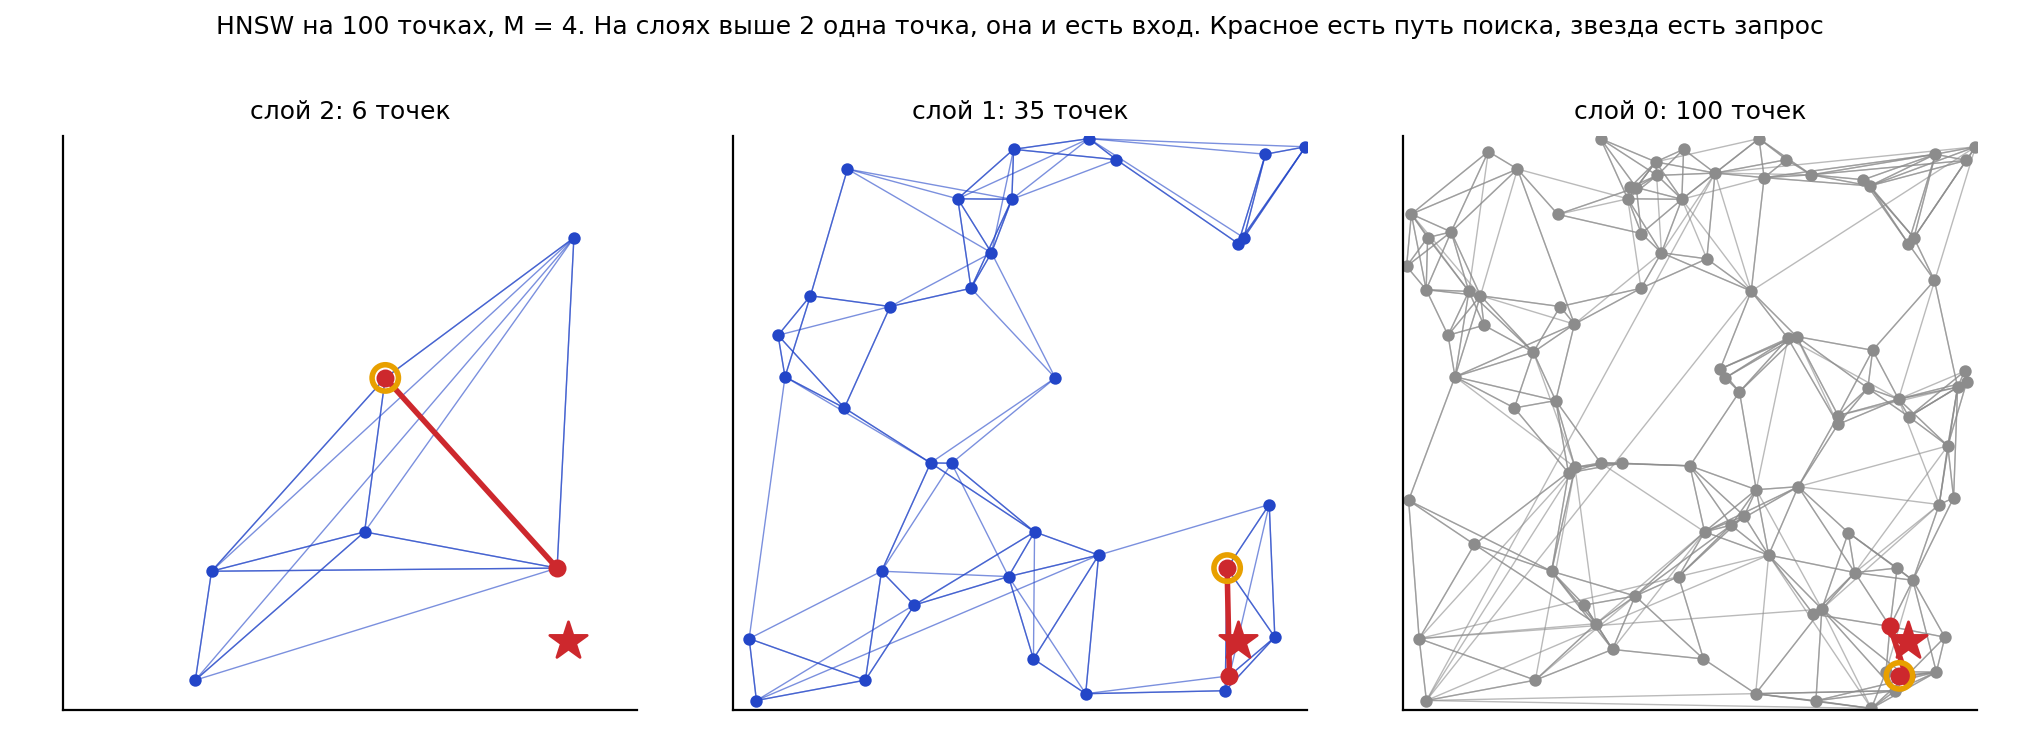

In [14]:
from toy_hnsw import ToyHNSW, recall_vs_ef
P = np.random.default_rng(0).random((100, 2))
h = ToyHNSW(M=4, ef_construction=16, seed=0)
for x in P: h.add(x)
print("точек на слоях:", [sum(1 for L in h.level if L >= l) for l in range(h.top + 1)])
trace = []; found = h.search([0.88, 0.12], k=1, ef=1, trace=trace)
print("найден", found, "| истинный ближайший", int(np.argmin(((P - [0.88, 0.12]) ** 2).sum(1))))
print("путь по слоям (слой, точка):", trace)
display(Image("img/fig_ann_hnsw_layers.png"))

In [15]:
rng3 = np.random.default_rng(3); X16 = rng3.normal(size=(2000, 16)); Q16 = rng3.normal(size=(100, 16))   # те же точки, что в материале
_, curve = recall_vs_ef(X16, Q16, k=10, M=8, efc=40, efs=(10, 20, 40, 80, 160))
pd.DataFrame(curve, columns=["ef", "полнота@10 против точного", "расстояний на запрос"]).round(3)

,ef,полнота@10 против точного,расстояний на запрос
0,10,0.757,159.72
1,20,0.872,232.52
2,40,0.949,357.91
3,80,0.987,562.41
4,160,0.993,853.03


## Шаг 7. Мини-практика: HNSW на 100 строфах

Задание программы курса: построить HNSW примерно на 100 векторах и показать влияние efSearch на полноту и задержку. Берём векторы BGE-M3 первых 100 строф. Каждая строфа служит запросом, ищем 10 соседей. Малое M = 4 и efConstruction = 16 делают эффект заметным на малой базе. Граф строится в один поток, и полнота воспроизводится точно.

In [16]:
import faiss
Xb = np.ascontiguousarray(E["bgem3"][:100].astype("float32")); d = Xb.shape[1]
flat = faiss.IndexFlatIP(d); flat.add(Xb); _, gt = flat.search(Xb, 10)
faiss.omp_set_num_threads(1)
hn = faiss.IndexHNSWFlat(d, 4, faiss.METRIC_INNER_PRODUCT); hn.hnsw.efConstruction = 16; hn.add(Xb)
out = []
for ef in [1, 2, 4, 8, 16, 32, 64, 128]:
    hn.hnsw.efSearch = ef
    t0 = time.perf_counter()
    for _ in range(20): _, I = hn.search(Xb, 10)
    ms = (time.perf_counter() - t0) / 20 / len(Xb) * 1e3
    rec = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(I, gt)])
    out.append({"efSearch": ef, "полнота@10": round(rec, 3), "мкс на запрос": round(ms * 1000, 1)})
mini = pd.DataFrame(out); mini

,efSearch,полнота@10,мкс на запрос
0,1,0.554,3.2
1,2,0.681,4.6
2,4,0.816,5.0
3,8,0.916,7.2
4,16,0.967,10.1
5,32,0.995,13.9
6,64,0.999,20.9
7,128,0.999,27.4


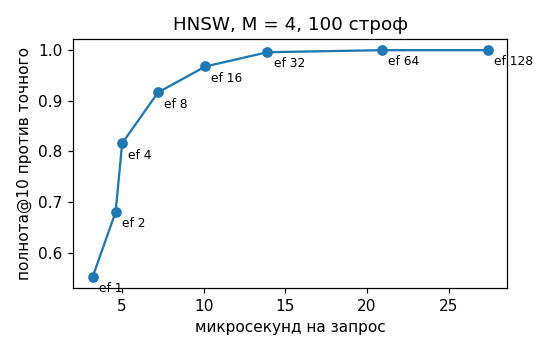

In [17]:
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(mini["мкс на запрос"], mini["полнота@10"], "o-")
for _, r in mini.iterrows(): ax.annotate(f"ef {int(r['efSearch'])}", (r["мкс на запрос"], r["полнота@10"]), xytext=(4, -10), textcoords="offset points", fontsize=8)
ax.set_xlabel("микросекунд на запрос"); ax.set_ylabel("полнота@10 против точного"); ax.set_title("HNSW, M = 4, 100 строф")
fig.tight_layout(); fig.savefig("img/nb_mini_practice.png", dpi=110); plt.close(fig); display(Image("img/nb_mini_practice.png"))

Вывод мини-практики записывается словами: при каком efSearch полнота достигает 0,95 и 1,0 и во сколько раз выросло время. На ста векторах точный перебор и так быстр. Мини-практика показывает механизм, выгода от HNSW появляется на сотнях тысяч векторов (шаг 8 и раздел 6.1 материала).

## Шаг 8. FAISS на 13 738 заголовках

Векторы заголовков ParaPhraser посчитаны программой `scripts/ann_bench.py` и лежат в `data/emb_headlines.npy`. 1000 заголовков служат запросами, остальные базой. Сравниваем точный перебор, IVF и HNSW в один поток.

In [18]:
H = np.load("data/emb_headlines.npy"); perm = np.random.default_rng(0).permutation(len(H))
xb, xq = np.ascontiguousarray(H[perm[1000:]]), np.ascontiguousarray(H[perm[:1000]]); d = xb.shape[1]
faiss.omp_set_num_threads(1)
flat = faiss.IndexFlatIP(d); flat.add(xb)
t0 = time.perf_counter(); _, gt = flat.search(xq, 10); t_flat = (time.perf_counter() - t0) / len(xq) * 1e3
def rec(I): return float(np.mean([len(set(a) & set(b)) / 10 for a, b in zip(I, gt)]))
rows_ = [{"индекс": "точный перебор", "настройка": "", "полнота@10": 1.0, "мс на запрос": round(t_flat, 3)}]
ivf = faiss.IndexIVFFlat(faiss.IndexFlatIP(d), d, 128, faiss.METRIC_INNER_PRODUCT); ivf.train(xb); ivf.add(xb)
for nprobe in [1, 4, 16, 64]:
    ivf.nprobe = nprobe; t0 = time.perf_counter(); _, I = ivf.search(xq, 10); ms = (time.perf_counter() - t0) / len(xq) * 1e3
    rows_.append({"индекс": "IVF, 128 кластеров", "настройка": f"nprobe {nprobe}", "полнота@10": round(rec(I), 3), "мс на запрос": round(ms, 3)})
hn = faiss.IndexHNSWFlat(d, 32, faiss.METRIC_INNER_PRODUCT); hn.hnsw.efConstruction = 40; hn.add(xb)
for ef in [8, 16, 32, 64, 128]:
    hn.hnsw.efSearch = ef; t0 = time.perf_counter(); _, I = hn.search(xq, 10); ms = (time.perf_counter() - t0) / len(xq) * 1e3
    rows_.append({"индекс": "HNSW, M = 32", "настройка": f"efSearch {ef}", "полнота@10": round(rec(I), 3), "мс на запрос": round(ms, 3)})
pd.DataFrame(rows_)

,индекс,настройка,полнота@10,мс на запрос
0,точный перебор,,1.000,0.559
1,"IVF, 128 кластеров",nprobe 1,0.533,0.015
2,"IVF, 128 кластеров",nprobe 4,0.793,0.043
3,"IVF, 128 кластеров",nprobe 16,0.947,0.139
4,"IVF, 128 кластеров",nprobe 64,0.995,0.546
5,"HNSW, M = 32",efSearch 8,0.935,0.038
6,"HNSW, M = 32",efSearch 16,0.973,0.055
7,"HNSW, M = 32",efSearch 32,0.990,0.087
8,"HNSW, M = 32",efSearch 64,0.997,0.146
9,"HNSW, M = 32",efSearch 128,0.999,0.262


Время зависит от машины, полнота воспроизводится. HNSW при efSearch около 32 находит 99 % истинных соседей в несколько раз быстрее перебора.

## Шаг 8а. Почти-дубликаты среди заголовков

Каждый из 14 738 заголовков служит запросом к индексу HNSW, ищется его ближайший сосед. Пары с косинусом от 0,9 суть кандидаты в почти-дубликаты.

In [19]:
heads = json.load(open("data/headlines.json", encoding="utf-8"))
Hn = np.ascontiguousarray(H.astype("float32"))
dd = faiss.IndexHNSWFlat(Hn.shape[1], 32, faiss.METRIC_INNER_PRODUCT); dd.hnsw.efSearch = 64
t0 = time.perf_counter(); dd.add(Hn); D2, I2 = dd.search(Hn, 2)
print(f"построение и поиск соседа для каждого заголовка: {time.perf_counter() - t0:.2f} с")
near = {}
for i in range(len(Hn)):
    for v, jj in zip(D2[i], I2[i]):
        if jj != i and jj >= 0: near.setdefault(frozenset((i, int(jj))), float(v))
hi = sorted(((v, tuple(k)) for k, v in near.items() if v >= 0.9), reverse=True)
print("пар с косинусом от 0,9:", len(hi))
for v, (a, b) in [x for x in hi if 0.94 <= x[0] < 0.95][:6]:
    print(round(v, 3), "|", heads[a], "|", heads[b])

построение и поиск соседа для каждого заголовка: 4.17 с
пар с косинусом от 0,9: 2383
0.95 | Экс-президента Египта Мурси приговорили к смертной казни | Суд приговорил бывшего президента Египта Мурси к смерти
0.95 | Российских работодателей заставят оплачивать отдых сотрудников. | Ростуризм предложил работодателям оплачивать отдых сотрудников в России.
0.95 | Бывший грузинский министр получил срок за беспорядки и пытки в тюрьме. | Бывший грузинский министр получил срок за беспорядки в тюрьме.
0.95 | Число жертв нового землетрясения в Непале возросло до 36 человек | Число жертв нового землетрясения в Непале увеличилось до 42
0.95 | В Новосибирске чемпион мира по каратэ найден мертвым | Пропавший в Новосибирске чемпион мира по каратэ найден мертвым
0.95 | Керри и Путин обсуждают в России Украину | Путин и Керри обсудили ситуацию на Украине 


Среди кандидатов есть одна новость другими словами и похожие сообщения с разными числами. Высокий косинус даёт кандидата в дубликаты, решение принимают по словам и числам (раздел 7.4 материала).

## Шаг 8б. Двоичные векторы

От каждой координаты вектора BGE-M3 остаётся только знак: 1024 бита, 128 байт вместо 4096. Сравним качество на 16 запросах к «Онегину».

In [20]:
Eb = np.sign(E["bgem3"]).astype("float32"); Qb = np.sign(Qv["bgem3"]).astype("float32")
ranks = lambda X, Qm: (lambda j, q: [ids[i] for i in np.argsort(-(X @ Qm[j]))[:10]])
pd.DataFrame({"float32, 4096 байт": evaluate(ranks(E["bgem3"], Qv["bgem3"]))[0],
              "знаки, точный запрос, 128 байт": evaluate(ranks(Eb, Qv["bgem3"]))[0],
              "знаки, двоичный запрос, 128 байт": evaluate(ranks(Eb, Qb))[0]}).T

,P@5,R@10,MRR,NDCG@10
"float32, 4096 байт",0.225,0.679,0.767,0.649
"знаки, точный запрос, 128 байт",0.213,0.596,0.844,0.644
"знаки, двоичный запрос, 128 байт",0.200,0.596,0.698,0.572


Знаки координат с точным запросом почти не теряют качества при сжатии в 32 раза: это асимметричное сравнение, как у PQ. Двоичный запрос теряет заметно больше. Для двоичных индексов в FAISS есть `IndexBinaryFlat` и `IndexBinaryHNSW`.

## Шаг 9. Инструмент `search_vectors` для агента

Описание инструмента сообщает модели, что он находит, чего не находит и насколько ему верить. Числа берутся из шага 2. Ответ ограничен по числу строк.

In [21]:
m_bge = res["bgem3"][0]
SEARCH_VECTORS = {
    "name": "search_vectors",
    "description": (f"Поиск по смыслу (модель BGE-M3, косинус) по строфам «Евгения Онегина». На выборке из 16 запросов "
                    f"NDCG@10 = {m_bge['NDCG@10']}, полнота в первой десятке {m_bge['R@10']}. Находит строфы по смыслу без общих слов: "
                    "персонажи, события, описания. Плохо находит точные цитаты: для цитат вызывай search_words. "
                    "Выдача не бывает пустой, низкий косинус не значит отсутствие ответа."),
    "parameters": {"query": "string", "k": "integer"},
}
hnsw_onegin = faiss.IndexHNSWFlat(E["bgem3"].shape[1], 32, faiss.METRIC_INNER_PRODUCT)
hnsw_onegin.add(np.ascontiguousarray(E["bgem3"].astype("float32"))); hnsw_onegin.hnsw.efSearch = 64

def search_vectors(query, k=5):
    v = bge.encode([query], normalize_embeddings=True).astype("float32")
    D, I = hnsw_onegin.search(v, min(int(k), 20))
    return json.dumps([{"строфа": ids[i], "первая строка": first[ids[i]], "косинус": round(float(s), 3)} for s, i in zip(D[0], I[0])], ensure_ascii=False)

print(SEARCH_VECTORS["description"], "\n")
print(search_vectors("кто такой Зарецкий", 3))

Поиск по смыслу (модель BGE-M3, косинус) по строфам «Евгения Онегина». На выборке из 16 запросов NDCG@10 = 0.649, полнота в первой десятке 0.679. Находит строфы по смыслу без общих слов: персонажи, события, описания. Плохо находит точные цитаты: для цитат вызывай search_words. Выдача не бывает пустой, низкий косинус не значит отсутствие ответа. 



[{"строфа": "6.IV", "первая строка": "Вперед, вперед, моя исторья!", "косинус": 0.485}, {"строфа": "6.XXVII", "первая строка": "Мой секундант? – сказал Евгений, —", "косинус": 0.432}, {"строфа": "6.XXVI", "первая строка": "Опершись на плотину, Ленский", "косинус": 0.425}]


Модель выбирает канал по описаниям: цитату отдаёт `search_words`, вопрос о персонаже `search_vectors`. Пометка ответа «найдено по смыслу: ранг r» сверяется с протоколом вызова так же, как пометка «найдено по словам».